<a href="https://colab.research.google.com/github/AliAkbariAlashti/Classical-Computer-Vision-Algorithms/blob/main/Learning_Semantic_Video_Search_with_CLIP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Learning Semantic Video Search with CLIP

*From video frames to embeddings, cosine similarity, timestamps, and searchable results*

This beginner-friendly notebook builds a small, end-to-end semantic video search prototype for **one uploaded MP4 video**. It samples timestamped frames, embeds them with CLIP, embeds a natural-language query, ranks frames by cosine similarity, and extracts a short clip around a selected result.

This is a learning prototype—not a production CCTV system. It deliberately leaves out live RTSP streams, multi-camera processing, detection/tracking pipelines, vector databases, APIs, and alerts. Those come later, after the ideas here feel concrete.

```mermaid
flowchart LR
    VIDEO[Video] --> FRAMES[Timestamped frames]
    FRAMES --> IMAGE[Image embeddings]
    QUERY[Text query] --> TEXT[Text embedding]
    IMAGE --> SIM[Cosine similarity]
    TEXT --> SIM
    SIM --> TOPK[Top K timestamps]
    TOPK --> CLIP[Result clip]
```

Recommended first experiment: a 20-second to 2-minute MP4. A T4 GPU is helpful, but the notebook also works on CPU for short videos.

## 1. Environment setup

We install only packages that are not reliably included in Colab. PyTorch, NumPy, scikit-learn, Matplotlib, Pillow, Pandas, and OpenCV are provided by Colab.

In [1]:
%pip install -q transformers accelerate ultralytics moviepy

In [2]:
import os
import random
import subprocess
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import transformers
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

# `files` is supplied by Google Colab. This message is clearer if the notebook is run elsewhere.
try:
    from google.colab import files
except ImportError:
    files = None
    print("This upload cell is intended for Google Colab.")

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# This makes the example repeatable where practical; it does not promise full GPU determinism.
print(f"Seed set to {SEED}")

Seed set to 42


In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
if device == "cpu":
    print("CPU fallback: embeddings will be slower. Use a shorter video or a larger sampling interval if needed.")

Using device: cuda


In [5]:
print({
    "OpenCV": cv2.__version__,
    "PyTorch": torch.__version__,
    "Transformers": transformers.__version__,
    "scikit-learn": sklearn.__version__,
    "NumPy": np.__version__,
})

{'OpenCV': '4.14.0', 'PyTorch': '2.14.1+cu130', 'Transformers': '5.22.1', 'scikit-learn': '1.6.1', 'NumPy': '2.4.6'}


## 2. Upload and inspect a video

A video is a sequence of images (frames). **FPS** is frames per second; total frame count is how many stored frames exist; duration is approximately `frame_count / FPS`; a frame index is its position in the sequence; and a timestamp tells us when it occurs. For constant-FPS video: `timestamp_seconds = frame_index / video_fps`.

Real CCTV timestamps can instead come from the camera or NVR clock, so they may not be reconstructed this way.

In [42]:
if files is None:
    raise RuntimeError("Run this notebook in Google Colab to use the upload widget.")

uploaded_files = files.upload()
mp4_files = [name for name in uploaded_files if name.lower().endswith(".mp4")]
if not mp4_files:
    raise ValueError("Please upload one MP4 file.")

VIDEO_PATH = mp4_files[0]
if len(mp4_files) > 1:
    print(f"Using the first MP4: {VIDEO_PATH}")
print(f"Selected video: {VIDEO_PATH}")

Saving Untitled design (1).mp4 to Untitled design (1).mp4
Selected video: Untitled design (1).mp4


,video_fps,frame_count,width,height,duration_seconds
0,30.0,1811,854,480,60.366667


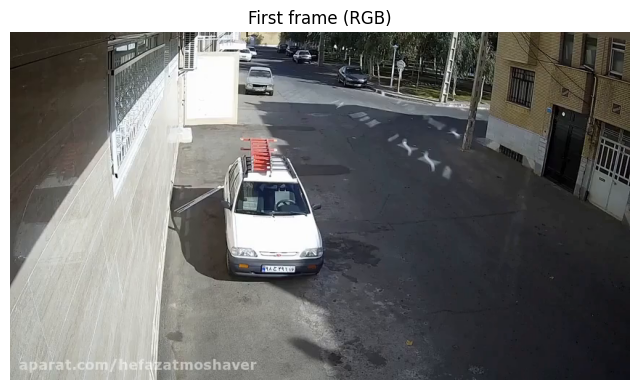

In [43]:
def get_video_metadata(video_path):
    """Read basic metadata and verify that OpenCV can decode the first frame."""
    capture = cv2.VideoCapture(str(video_path))
    try:
        if not capture.isOpened():
            raise ValueError(f"OpenCV could not open: {video_path}")
        video_fps = float(capture.get(cv2.CAP_PROP_FPS))
        frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
        readable, first_frame_bgr = capture.read()
        if not readable or first_frame_bgr is None:
            raise ValueError("The file opened, but OpenCV could not decode its first frame.")
        if not np.isfinite(video_fps) or video_fps <= 0:
            raise ValueError(f"Invalid FPS metadata ({video_fps}). Cannot calculate timestamps safely.")
        duration_seconds = frame_count / video_fps
        return {
            "video_fps": video_fps,
            "frame_count": frame_count,
            "width": width,
            "height": height,
            "duration_seconds": duration_seconds,
            "first_frame_rgb": cv2.cvtColor(first_frame_bgr, cv2.COLOR_BGR2RGB),
        }
    finally:
        capture.release()

video_metadata = get_video_metadata(VIDEO_PATH)
VIDEO_DURATION_SECONDS = video_metadata["duration_seconds"]
metadata_table = pd.DataFrame([{key: value for key, value in video_metadata.items() if key != "first_frame_rgb"}])
display(metadata_table)

plt.figure(figsize=(8, 5))
plt.imshow(video_metadata["first_frame_rgb"])
plt.title("First frame (RGB)")
plt.axis("off")
plt.show()

**Reflection:** If this video reports 30 FPS, how many frames are stored in ten seconds? Why might we avoid embedding all of them for a first prototype?

## 3. Sample timestamped frames

Instead of analyzing every frame, we take one representative frame at a configurable interval. A smaller interval gives better temporal coverage but costs more compute and storage. A larger interval is cheaper but can miss short events. Each sampled record keeps the original frame index, its timestamp, and the RGB image.

Sampled 61 frames every 1 seconds.


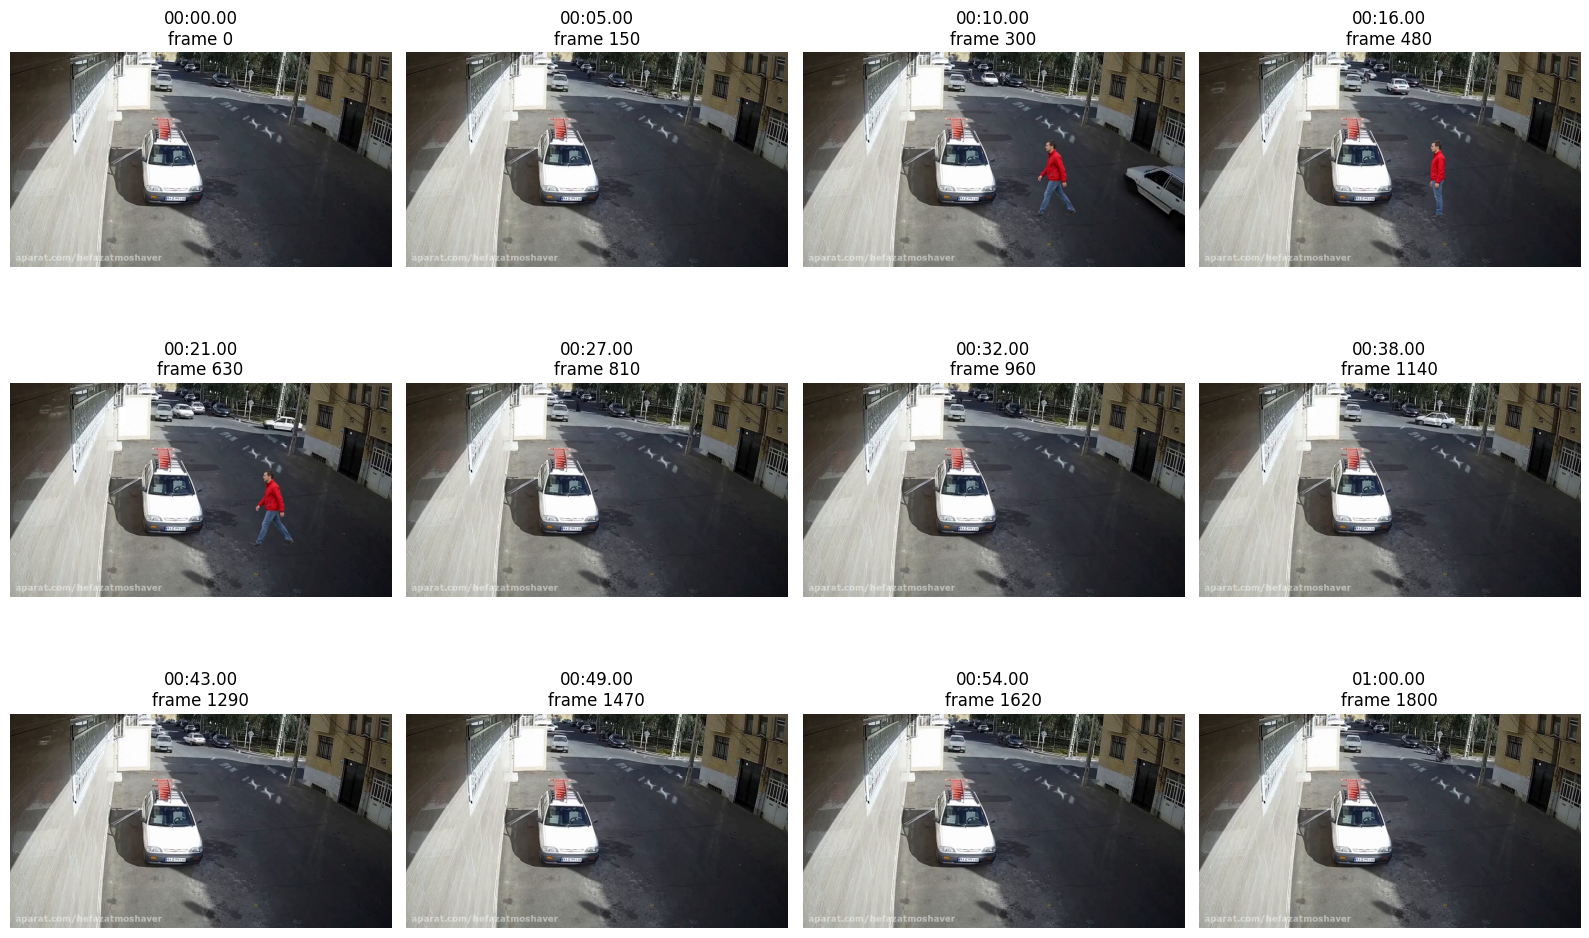

In [44]:
SAMPLE_EVERY_SECONDS = 1.0

def sample_video_frames(video_path, sample_every_seconds):
    """Sample safely by frame index and return timestamped RGB records."""
    if sample_every_seconds <= 0:
        raise ValueError("sample_every_seconds must be greater than zero.")

    capture = cv2.VideoCapture(str(video_path))
    try:
        if not capture.isOpened():
            raise ValueError(f"OpenCV could not open: {video_path}")
        video_fps = float(capture.get(cv2.CAP_PROP_FPS))
        if not np.isfinite(video_fps) or video_fps <= 0:
            raise ValueError(f"Invalid FPS metadata ({video_fps}); cannot sample safely.")

        frame_step = max(1, int(round(sample_every_seconds * video_fps)))
        frame_records = []
        frame_index = 0
        while True:
            readable, frame_bgr = capture.read()
            if not readable:
                break
            if frame_index % frame_step == 0:
                timestamp_seconds = frame_index / video_fps
                frame_records.append({
                    "frame_index": frame_index,
                    "timestamp_seconds": timestamp_seconds,
                    "image_rgb": cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB),
                })
            frame_index += 1
    finally:
        capture.release()

    if not frame_records:
        raise ValueError("No frames were sampled from this video.")
    print(f"Sampled {len(frame_records)} frames every {sample_every_seconds:g} seconds.")
    return frame_records

def format_timestamp(seconds):
    minutes, remaining_seconds = divmod(float(seconds), 60)
    return f"{int(minutes):02d}:{remaining_seconds:05.2f}"

def display_sampled_frames(frame_records, max_frames=12):
    """Display evenly selected timestamped frames without changing the records."""
    if not frame_records:
        print("No sampled frames to display.")
        return
    shown_indices = np.linspace(0, len(frame_records) - 1, min(max_frames, len(frame_records)), dtype=int)
    columns = min(4, len(shown_indices))
    rows = int(np.ceil(len(shown_indices) / columns))
    figure, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.5 * rows))
    for axis, record_index in zip(np.atleast_1d(axes).ravel(), shown_indices):
        record = frame_records[record_index]
        axis.imshow(record["image_rgb"])
        axis.set_title(f"{format_timestamp(record['timestamp_seconds'])}\nframe {record['frame_index']}")
        axis.axis("off")
    for axis in np.atleast_1d(axes).ravel()[len(shown_indices):]:
        axis.axis("off")
    plt.tight_layout()
    plt.show()

frame_records = sample_video_frames(VIDEO_PATH, SAMPLE_EVERY_SECONDS)
display_sampled_frames(frame_records, max_frames=12)

In [45]:
# This only estimates/compares sample counts; it does not create embeddings.
intervals_to_compare = [0.5, 1.0, 2.0, 5.0]
video_fps = video_metadata["video_fps"]
frame_count = video_metadata["frame_count"]
comparison_rows = []
for interval in intervals_to_compare:
    step = max(1, int(round(interval * video_fps)))
    sample_count = len(range(0, frame_count, step))
    comparison_rows.append({"interval_seconds": interval, "estimated_sampled_frames": sample_count})
display(pd.DataFrame(comparison_rows))

,interval_seconds,estimated_sampled_frames
0,0.5,121
1,1.0,61
2,2.0,31
3,5.0,13


**Reflection:** Which interval would you choose for a five-minute video if a person might only be visible for one second? What cost would that choice add?

## 4. Object detection versus semantic search

These are related but different tasks. Detection asks what objects are present and where. Semantic search asks which image best matches a sentence. Tracking asks whether the same object persists across time. Event understanding asks what happened across an interval.

| Task | Typical output | Example question |
|---|---|---|
| Object detection | boxes, labels, confidence | Where are the cars? |
| Semantic search | ranked frames or clips | Find someone carrying a bag |
| Tracking | object IDs over time | Is this the same car? |
| Event understanding | event interval and evidence | Did a person enter the room? |

The optional YOLO demo below is independent: it does not affect CLIP retrieval.

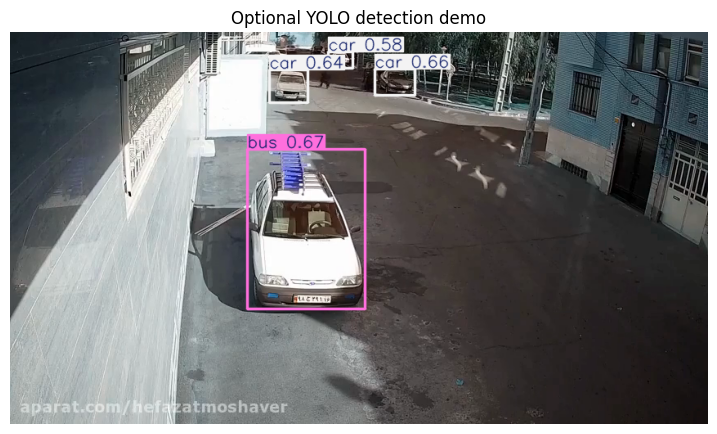

Detected objects: ['bus', 'car', 'car', 'car']


In [46]:
RUN_OPTIONAL_YOLO_DEMO = True

if RUN_OPTIONAL_YOLO_DEMO:
    from ultralytics import YOLO

    yolo_model = YOLO("yolo11n.pt")
    selected_frame = frame_records[len(frame_records) // 2]["image_rgb"]
    yolo_result = yolo_model(selected_frame, verbose=False)[0]
    annotated_rgb = cv2.cvtColor(yolo_result.plot(), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(9, 6))
    plt.imshow(annotated_rgb)
    plt.title("Optional YOLO detection demo")
    plt.axis("off")
    plt.show()
    detected_objects = [yolo_result.names[int(class_id)] for class_id in yolo_result.boxes.cls.tolist()]
    print("Detected objects:", detected_objects or "none")
else:
    print("YOLO demo skipped. Set RUN_OPTIONAL_YOLO_DEMO = True to run it.")

**Reflection:** Why could a detector find a `person` but still not answer whether that person is *entering a room*?

## 5. Load CLIP

CLIP has an image encoder and a text encoder. Both produce vectors in one shared space: similar meanings should point in similar directions. A vector is not a readable list of labels; it is a learned, compressed representation. We use a pretrained model—this notebook does not train anything.

In [47]:
from transformers import CLIPModel, CLIPProcessor

MODEL_NAME = "openai/clip-vit-base-patch32"
processor = CLIPProcessor.from_pretrained(MODEL_NAME)
model = CLIPModel.from_pretrained(MODEL_NAME).to(device)
model.eval()
print(f"Loaded {MODEL_NAME} on {device}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loaded openai/clip-vit-base-patch32 on cuda


## 6. Create image embeddings

We encode images in small batches so we do not need to hold all model inputs in accelerator memory. After CLIP creates each embedding, we normalize it to length one. Normalization makes the dot product equal cosine similarity later.

In [48]:
IMAGE_BATCH_SIZE = 16

def encode_images(images, model, processor, device, batch_size=16):
    """Return L2-normalized CLIP image embeddings on CPU, one row per RGB image."""
    if not images:
        raise ValueError("images must contain at least one frame.")
    normalized_batches = []
    original_norms = []

    for start_index in range(0, len(images), batch_size):
        image_batch = images[start_index : start_index + batch_size]
        pil_batch = [Image.fromarray(image) if isinstance(image, np.ndarray) else image for image in image_batch]
        model_inputs = processor(images=pil_batch, return_tensors="pt")
        model_inputs = {name: tensor.to(device) for name, tensor in model_inputs.items()}
        with torch.inference_mode():
            features = model.get_image_features(**model_inputs)
            # If features is a Hugging Face output object, extract the tensor
            if hasattr(features, "image_embeds"):
                features = features.image_embeds
            elif not isinstance(features, torch.Tensor) and hasattr(features, "pooler_output"):
                features = features.pooler_output
            norms = torch.linalg.vector_norm(features, dim=1, keepdim=True)
            normalized_features = features / norms.clamp_min(1e-12)
        original_norms.extend(norms.squeeze(1).detach().cpu().tolist())
        normalized_batches.append(normalized_features.cpu())

    embeddings = torch.cat(normalized_batches, dim=0)
    return embeddings, original_norms

images_rgb = [record["image_rgb"] for record in frame_records]
image_embeddings, image_embedding_original_norms = encode_images(
    images_rgb, model, processor, device, IMAGE_BATCH_SIZE
)
assert image_embeddings.shape[0] == len(frame_records), "Every sampled frame needs one embedding."

embedding_memory_mib = image_embeddings.numel() * image_embeddings.element_size() / (1024 ** 2)
print(f"Embedding matrix shape: {tuple(image_embeddings.shape)}")
print("First 10 values of first embedding:", image_embeddings[0, :10].numpy())
print(f"First embedding norm before normalization: {image_embedding_original_norms[0]:.4f}")
print(f"First embedding norm after normalization: {torch.linalg.vector_norm(image_embeddings[0]).item():.4f}")
print(f"Approximate embedding-matrix memory: {embedding_memory_mib:.3f} MiB")

Embedding matrix shape: (61, 512)
First 10 values of first embedding: [  0.0049103  8.3195e-05    0.047929    -0.01413    0.018588   -0.043532    0.019306   -0.012462   -0.034625  -0.0060258]
First embedding norm before normalization: 10.4643
First embedding norm after normalization: 1.0000
Approximate embedding-matrix memory: 0.119 MiB


The embedding is a compressed semantic representation, not the original image. Notice that storing embeddings is far smaller than storing every full-resolution frame.

**Reflection:** Why might image embeddings be useful even when we do not yet know the learner's future query?

## 7. Visualize the embedding space

CLIP's real embedding space has many dimensions. PCA compresses it to two dimensions only for visualization. Nearby dots may be visually or semantically related, but this projection cannot preserve every original distance perfectly.

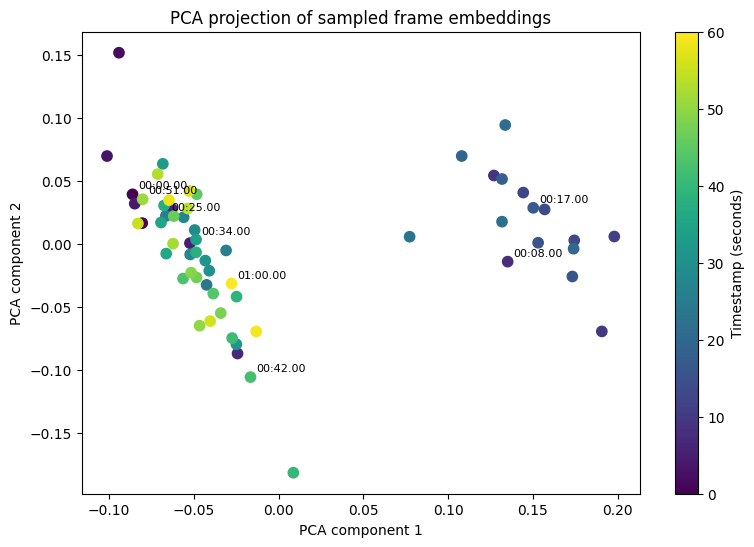

In [49]:
if len(frame_records) < 3:
    print("PCA needs at least three sampled frames. Use a longer video or a smaller sampling interval.")
else:
    pca = PCA(n_components=2, random_state=SEED)
    embedding_points_2d = pca.fit_transform(image_embeddings.numpy())
    timestamps = np.array([record["timestamp_seconds"] for record in frame_records])

    plt.figure(figsize=(9, 6))
    scatter = plt.scatter(embedding_points_2d[:, 0], embedding_points_2d[:, 1], c=timestamps, cmap="viridis", s=55)
    plt.colorbar(scatter, label="Timestamp (seconds)")
    annotation_indices = np.linspace(0, len(frame_records) - 1, min(8, len(frame_records)), dtype=int)
    for index in annotation_indices:
        plt.annotate(format_timestamp(timestamps[index]), embedding_points_2d[index], xytext=(4, 4), textcoords="offset points", fontsize=8)
    plt.title("PCA projection of sampled frame embeddings")
    plt.xlabel("PCA component 1")
    plt.ylabel("PCA component 2")
    plt.show()

**Reflection:** Find two nearby and two distant points. Do their source frames look meaningfully similar or different?

## 8. Encode a text query

Text travels through CLIP's text encoder into the same kind of shared space as images. Start with the example below, then replace it with something that actually exists in your uploaded video.

In [50]:
def encode_text(query, model, processor, device):
    """Return one L2-normalized CLIP text embedding on CPU."""
    if not isinstance(query, str) or not query.strip():
        raise ValueError("query must be a non-empty string.")
    text_inputs = processor(text=[query], return_tensors="pt", padding=True)
    text_inputs = {name: tensor.to(device) for name, tensor in text_inputs.items()}
    with torch.inference_mode():
        text_features = model.get_text_features(**text_inputs)
        # If text_features is a Hugging Face output object, extract the tensor
        if hasattr(text_features, "text_embeds"):
            text_features = text_features.text_embeds
        elif not isinstance(text_features, torch.Tensor) and hasattr(text_features, "pooler_output"):
            text_features = text_features.pooler_output
        text_embedding = text_features / torch.linalg.vector_norm(text_features, dim=1, keepdim=True).clamp_min(1e-12)
    return text_embedding.cpu()

QUERY = "a person walking near a car"
text_embedding = encode_text(QUERY, model, processor, device)
print(f"Query: {QUERY!r}")
print(f"Text embedding shape: {tuple(text_embedding.shape)}")
print(f"Text embedding norm: {torch.linalg.vector_norm(text_embedding).item():.4f}")

Query: 'a person walking near a car'
Text embedding shape: (1, 512)
Text embedding norm: 1.0000


## 9. Calculate cosine similarity manually

Cosine similarity measures the angle between two vectors. Once both vectors are normalized to length one, cosine similarity becomes a simple dot product. Larger values mean a closer match **relative to this candidate set**. CLIP scores are ranking signals—not accuracy percentages—and even the highest score can be wrong.

In [51]:
# Shapes are [frames, dimensions] and [1, dimensions]. The transpose gives [dimensions, 1].
similarities = image_embeddings @ text_embedding.T
similarities = similarities.squeeze(1)

first_dot_product_score = similarities[0].item()
first_helper_score = cosine_similarity(
    image_embeddings[0].numpy().reshape(1, -1),
    text_embedding.numpy()
)[0, 0]
print(f"First-frame dot-product score: {first_dot_product_score:.6f}")
print(f"First-frame cosine_similarity score: {first_helper_score:.6f}")
np.testing.assert_allclose(first_dot_product_score, first_helper_score, rtol=1e-5, atol=1e-6)
print("The manual dot product and cosine helper agree.")

First-frame dot-product score: 0.291680
First-frame cosine_similarity score: 0.291680
The manual dot product and cosine helper agree.


**Reflection:** If the best two scores are very close, what should an operator do before trusting the top one?

## 10. Retrieve Top K results

Top K retrieval sorts the candidate frames by similarity and returns the best few. Showing several results is helpful: the first result may not be the only plausible moment.

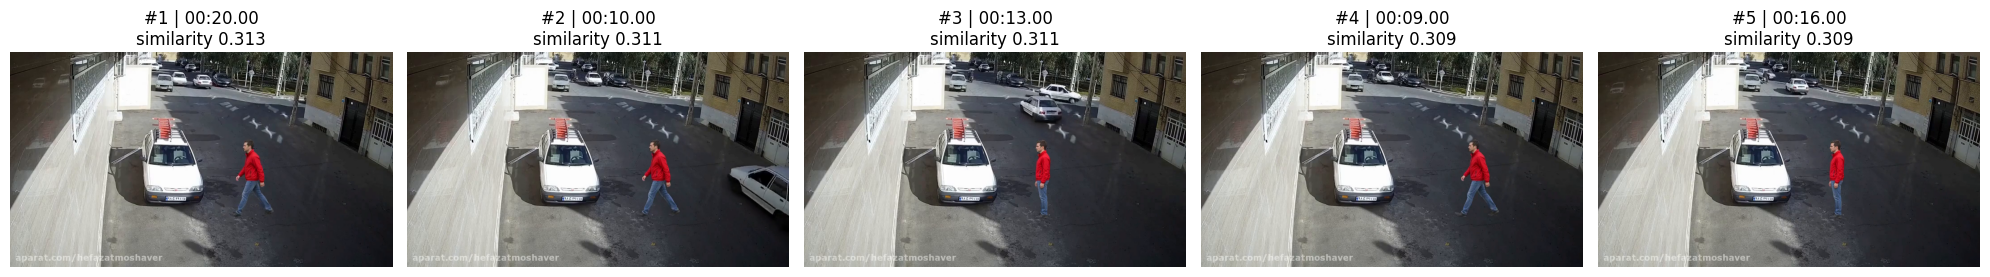

,rank,frame_index,timestamp,timestamp_seconds,similarity
0,1,600,00:20.00,20.0,0.3133
1,2,300,00:10.00,10.0,0.3112
2,3,390,00:13.00,13.0,0.3107
3,4,270,00:09.00,9.0,0.3088
4,5,480,00:16.00,16.0,0.3087


In [52]:
TOP_K = 5

def search_video(query, frame_records, image_embeddings, model, processor, device, top_k=5):
    """Encode a query once and return highest-scoring frame records."""
    if len(frame_records) != image_embeddings.shape[0]:
        raise ValueError("frame_records and image_embeddings must have the same length.")
    if top_k < 1:
        raise ValueError("top_k must be at least 1.")
    query_embedding = encode_text(query, model, processor, device)
    query_scores = (image_embeddings @ query_embedding.T).squeeze(1)
    result_count = min(top_k, len(frame_records))
    top_indices = torch.topk(query_scores, k=result_count).indices.tolist()

    results = []
    for rank, record_index in enumerate(top_indices, start=1):
        record = frame_records[record_index]
        results.append({
            "rank": rank,
            "frame_index": record["frame_index"],
            "timestamp_seconds": record["timestamp_seconds"],
            "similarity": float(query_scores[record_index]),
            "image_rgb": record["image_rgb"],
        })
    return results

def display_search_results(results):
    """Show result images and a separate table that does not contain image arrays."""
    if not results:
        print("No results to display.")
        return
    figure, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 4))
    for axis, result in zip(np.atleast_1d(axes), results):
        axis.imshow(result["image_rgb"])
        axis.set_title(
            f"#{result['rank']} | {format_timestamp(result['timestamp_seconds'])}\n"
            f"similarity {result['similarity']:.3f}"
        )
        axis.axis("off")
    plt.tight_layout()
    plt.show()

    result_table = pd.DataFrame([{
        "rank": result["rank"],
        "frame_index": result["frame_index"],
        "timestamp": format_timestamp(result["timestamp_seconds"]),
        "timestamp_seconds": round(result["timestamp_seconds"], 3),
        "similarity": round(result["similarity"], 4),
    } for result in results])
    display(result_table)

results = search_video(QUERY, frame_records, image_embeddings, model, processor, device, TOP_K)
display_search_results(results)

## 11. Interactive query experiments

Video preprocessing was the expensive step. These queries reuse the image embeddings already in memory, so each new search only encodes a short sentence and compares small vectors. Adapt these example sentences to your video.


Query: a man walking


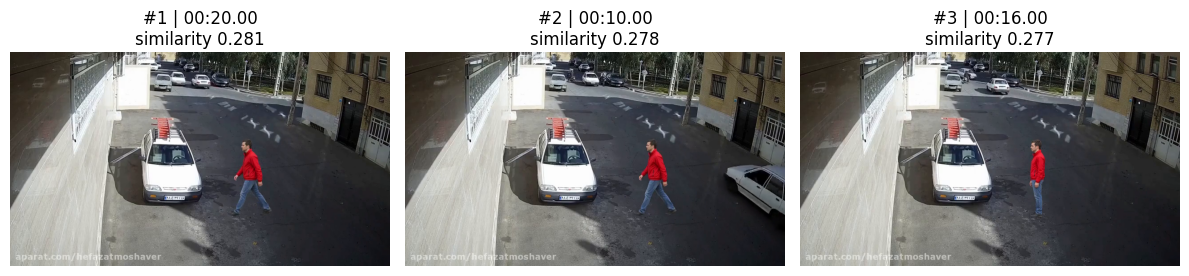

,rank,frame_index,timestamp,timestamp_seconds,similarity
0,1,600,00:20.00,20.0,0.2814
1,2,300,00:10.00,10.0,0.2784
2,3,480,00:16.00,16.0,0.2765



Query: a man standing


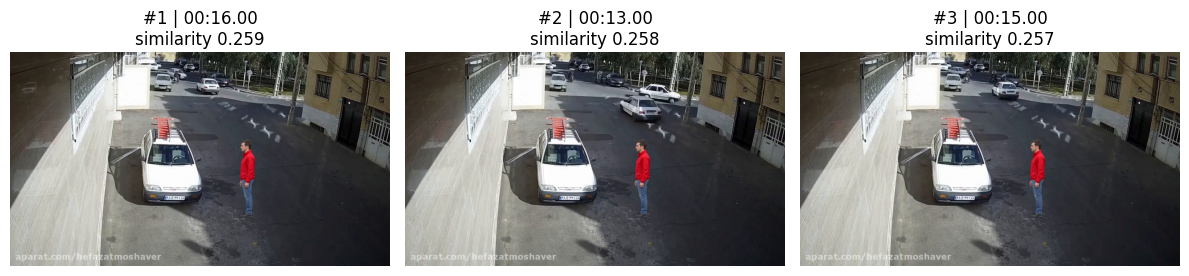

,rank,frame_index,timestamp,timestamp_seconds,similarity
0,1,480,00:16.00,16.0,0.2592
1,2,390,00:13.00,13.0,0.2578
2,3,450,00:15.00,15.0,0.2571


In [57]:
example_queries = [
    "a man walking",
    "a man standing"
    ]

# Run at least three queries against the same precomputed image embeddings.
for experiment_query in example_queries[:3]:
    print(f"\nQuery: {experiment_query}")
    experiment_results = search_video(
        experiment_query, frame_records, image_embeddings, model, processor, device, top_k=3
    )
    display_search_results(experiment_results)

# Guaranteed fallback: edit this string and run this cell again.
CUSTOM_QUERY = "describe something visible in my uploaded video"
# display_search_results(search_video(CUSTOM_QUERY, frame_records, image_embeddings, model, processor, device, top_k=TOP_K))

In [58]:
# Optional convenience widget. The normal function-call cell above remains the reliable fallback.
try:
    import ipywidgets as widgets
    from IPython.display import display as ipython_display

    query_box = widgets.Text(value=QUERY, description="Query:", layout=widgets.Layout(width="70%"))
    search_button = widgets.Button(description="Search video", button_style="primary")
    output_area = widgets.Output()

    def on_search_button_clicked(_):
        with output_area:
            output_area.clear_output(wait=True)
            widget_results = search_video(query_box.value, frame_records, image_embeddings, model, processor, device, TOP_K)
            display_search_results(widget_results)

    search_button.on_click(on_search_button_clicked)
    ipython_display(widgets.VBox([widgets.HBox([query_box, search_button]), output_area]))
except Exception as widget_error:
    print(f"Widget unavailable ({widget_error}). Use CUSTOM_QUERY in the previous cell.")

**Reflection:** Try one concrete noun query and one action query. Which kind gives more convincing results, and why might a single still frame struggle with actions?

## 12. Extract a clip around a result

A retrieved frame identifies a candidate moment. The surrounding clip gives an operator the temporal context to decide what actually happened. We clamp the clip to the beginning and end of the source video and leave the original file unchanged.

In [59]:
from IPython.display import Video, display as ipython_display

CLIP_BEFORE_SECONDS = 2.0
CLIP_AFTER_SECONDS = 2.0

def extract_result_clip(video_path, center_timestamp, before_seconds, after_seconds, output_path):
    """Extract an MP4 around a result with FFmpeg and return its clamped bounds."""
    if before_seconds < 0 or after_seconds < 0:
        raise ValueError("before_seconds and after_seconds must be non-negative.")
    metadata = get_video_metadata(video_path)
    duration_seconds = metadata["duration_seconds"]
    start_seconds = max(0.0, float(center_timestamp) - before_seconds)
    end_seconds = min(duration_seconds, float(center_timestamp) + after_seconds)
    if end_seconds <= start_seconds:
        raise ValueError("The requested clip has no positive duration.")

    output_path = str(output_path)
    command = [
        "ffmpeg", "-y", "-ss", f"{start_seconds:.3f}", "-i", str(video_path),
        "-t", f"{end_seconds - start_seconds:.3f}", "-c:v", "libx264", "-c:a", "aac", "-movflags", "+faststart", output_path,
    ]
    subprocess.run(command, check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    print(f"Extracted clip from {format_timestamp(start_seconds)} to {format_timestamp(end_seconds)}")
    return output_path, start_seconds, end_seconds

# Choose any rank from the most recent `results` list (1 means the highest-scoring frame).
SELECTED_RESULT_RANK = 1
selected_result = results[SELECTED_RESULT_RANK - 1]
RESULT_CLIP_PATH = "semantic_search_result_clip.mp4"

clip_path, clip_start, clip_end = extract_result_clip(
    VIDEO_PATH,
    selected_result["timestamp_seconds"],
    CLIP_BEFORE_SECONDS,
    CLIP_AFTER_SECONDS,
    RESULT_CLIP_PATH,
)
ipython_display(Video(clip_path, embed=True))

Extracted clip from 00:18.00 to 00:22.00


**Reflection:** Did the short clip change your judgment of the frame-level result? What information was missing from the still image?

## 13. Failure analysis

Semantic frame search is useful, but it is not ground truth. It can fail when a short event occurs between samples; scenes look alike but mean different things; an action needs motion; objects are small, occluded, blurred, or poorly lit; general web-image training differs from CCTV; language is ambiguous; several moments are correct; or the leading scores are nearly tied.

Use the cell below to inspect a result that seems wrong. Write a brief hypothesis before changing sampling or the query.

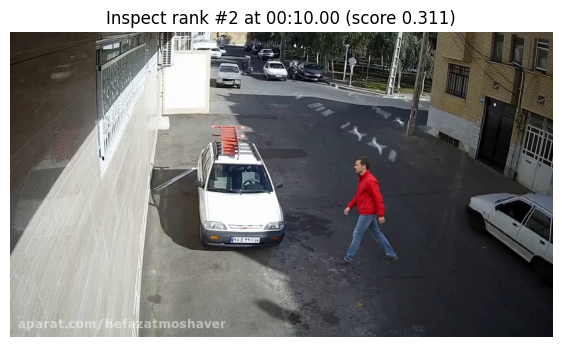

Your failure-analysis note: Replace this text: for example, the query describes an action that a single sampled frame cannot show.


In [60]:
# Experiment: choose an incorrect (or surprising) rank and record why it may have failed.
INCORRECT_RESULT_RANK = min(2, len(results))
incorrect_result = results[INCORRECT_RESULT_RANK - 1]
plt.figure(figsize=(7, 4))
plt.imshow(incorrect_result["image_rgb"])
plt.title(
    f"Inspect rank #{incorrect_result['rank']} at {format_timestamp(incorrect_result['timestamp_seconds'])} "
    f"(score {incorrect_result['similarity']:.3f})"
)
plt.axis("off")
plt.show()

FAILURE_NOTE = "Replace this text: for example, the query describes an action that a single sampled frame cannot show."
print("Your failure-analysis note:", FAILURE_NOTE)

## 14. Connect this notebook to the future MVP

This notebook intentionally stops at frame-level retrieval. A practical system adds temporal context, identity, metadata, scale, and verification.

| Learning notebook | Production MVP evolution |
|---|---|
| Uploaded MP4 | RTSP camera and NVR streams |
| One frame every second | Configurable sampling plus motion and event gating |
| CLIP frame embedding | Event, crop, and clip embeddings |
| Python list of vectors | pgvector or Qdrant index |
| Text query | Hybrid text, image, time, camera, and metadata query |
| Top K frames | Top K events and clips |
| Manual inspection | VLM verification and temporal grounding |
| No object identity | Detection, tracking, and track IDs |
| No live alerts | Zone rules and real-time monitoring |

Future pipeline:

```text
RTSP stream
  -> lightweight detection and tracking
  -> event creation
  -> event keyframes and embeddings
  -> semantic index
  -> natural-language retrieval
  -> Top K VLM verification
  -> evidence-backed result or live alert
```

You now have the core learning loop: represent video as timestamped frames, map frames and language into comparable embeddings, rank with cosine similarity, and inspect a short clip around a promising moment.